# Domain: Healthcare

## Context of Dataset

This dataset is used to predict the presence of **heart disease** in a patient based on clinical measurements.

The raw data is split across two files that share a common key (`patient_id`):
- **`values.csv`** — the feature/predictor variables (13 clinical attributes per patient).
- **`labels.csv`** — the target variable, `heart_disease_present` (1 = disease present, 0 = no disease).

Attribute information (from `values.csv`):
- `slope_of_peak_exercise_st_segment` — slope of the peak exercise ST segment (categorical, 1–3)
- `thal` — thallium stress test result (`normal`, `fixed_defect`, `reversible_defect`)
- `resting_blood_pressure` — resting blood pressure (mm Hg)
- `chest_pain_type` — chest pain type (categorical, 1–4)
- `num_major_vessels` — number of major vessels colored by fluoroscopy (0–3)
- `fasting_blood_sugar_gt_120_mg_per_dl` — fasting blood sugar > 120 mg/dl (1 = true, 0 = false)
- `resting_ekg_results` — resting electrocardiographic results (categorical, 0–2)
- `serum_cholesterol_mg_per_dl` — serum cholesterol (mg/dl)
- `oldpeak_eq_st_depression` — ST depression induced by exercise relative to rest
- `sex` — 1 = male, 0 = female
- `age` — age in years
- `max_heart_rate_achieved` — maximum heart rate achieved
- `exercise_induced_angina` — 1 = yes, 0 = no

Target (from `labels.csv`):
- `heart_disease_present` — 1 = patient has heart disease, 0 = patient does not

## Task 1: Data Analysis Report
## Step 1: Loading the Dataset

In [5]:
# Importing required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              ConfusionMatrixDisplay)
import pickle
import random

In [6]:
# NOTE (fix vs. Liver notebook): avoid hardcoding an absolute, machine-specific path.
# Both files are expected to sit alongside this notebook (or update the path below).

values_path = '/Users/anmolgupta/Desktop/Datamites Internship/Heart_Disease_Prediction (PRCP-1016)/values.csv'  # feature file (13 clinical attributes per patient)
labels_path = '/Users/anmolgupta/Desktop/Datamites Internship/Heart_Disease_Prediction (PRCP-1016)/labels.csv'   # target file (heart_disease_present)

In [7]:
values = pd.read_csv(values_path)   # feature columns
labels = pd.read_csv(labels_path)   # target column

print('values shape:', values.shape)
print('labels shape:', labels.shape)

values shape: (180, 14)
labels shape: (180, 2)


#### Concatenating the two files

Both files share the `patient_id` key, one row per patient. We use an **inner merge on `patient_id`**
(rather than a positional `pd.concat`) so rows are matched correctly even if the row order ever differs
between the two files — a positional concat would silently mismatch patients and labels if that happened.

In [9]:
# Merge (not a positional concat) on the shared key so labels always line up with the right patient

original_data = values.merge(labels, on='patient_id', how='inner')
print(original_data.shape)
original_data.head()

(180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [10]:
df = original_data.copy()  # working copy so the original merged data stays untouched
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


## Step 2: Initial Basic Checks

In [12]:
df.shape

(180, 15)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [14]:
# patient_id is just a row identifier, not a predictive feature — drop it now so it
# never accidentally leaks into scaling/encoding/model steps later.

df = df.drop(columns=['patient_id'])
df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [15]:
df.isnull().sum()   # check for missing values

slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [16]:
df.duplicated().sum()   # check for duplicate rows

0

In [17]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [18]:
df['heart_disease_present'].value_counts()

heart_disease_present
0    100
1     80
Name: count, dtype: int64

In [19]:
df['heart_disease_present'].value_counts(normalize=True) * 100   # class balance in %

heart_disease_present
0    55.555556
1    44.444444
Name: proportion, dtype: float64

#### Note:

The target variable is `heart_disease_present` (1 = disease present, 0 = no disease).
The classes are **mildly imbalanced** (roughly 56% / 44%) — noticeably less severe than the liver dataset's
imbalance, but still worth correcting for during training (handled with SMOTE, and by stratifying the
train/test split, in the Feature Engineering step below).

There are **no missing values and no duplicate rows** in this dataset, so no null-imputation or
de-duplication step is required — unlike the liver dataset. We still keep the null/duplicate checks in the
notebook as a standard, reusable sanity check.

## Step 3: EDA — Univariate & Bivariate Analysis

### 1. Univariate Analysis

In [23]:
num_col = df.select_dtypes(include=['number']).columns
num_col

Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

#### Plotting Histograms

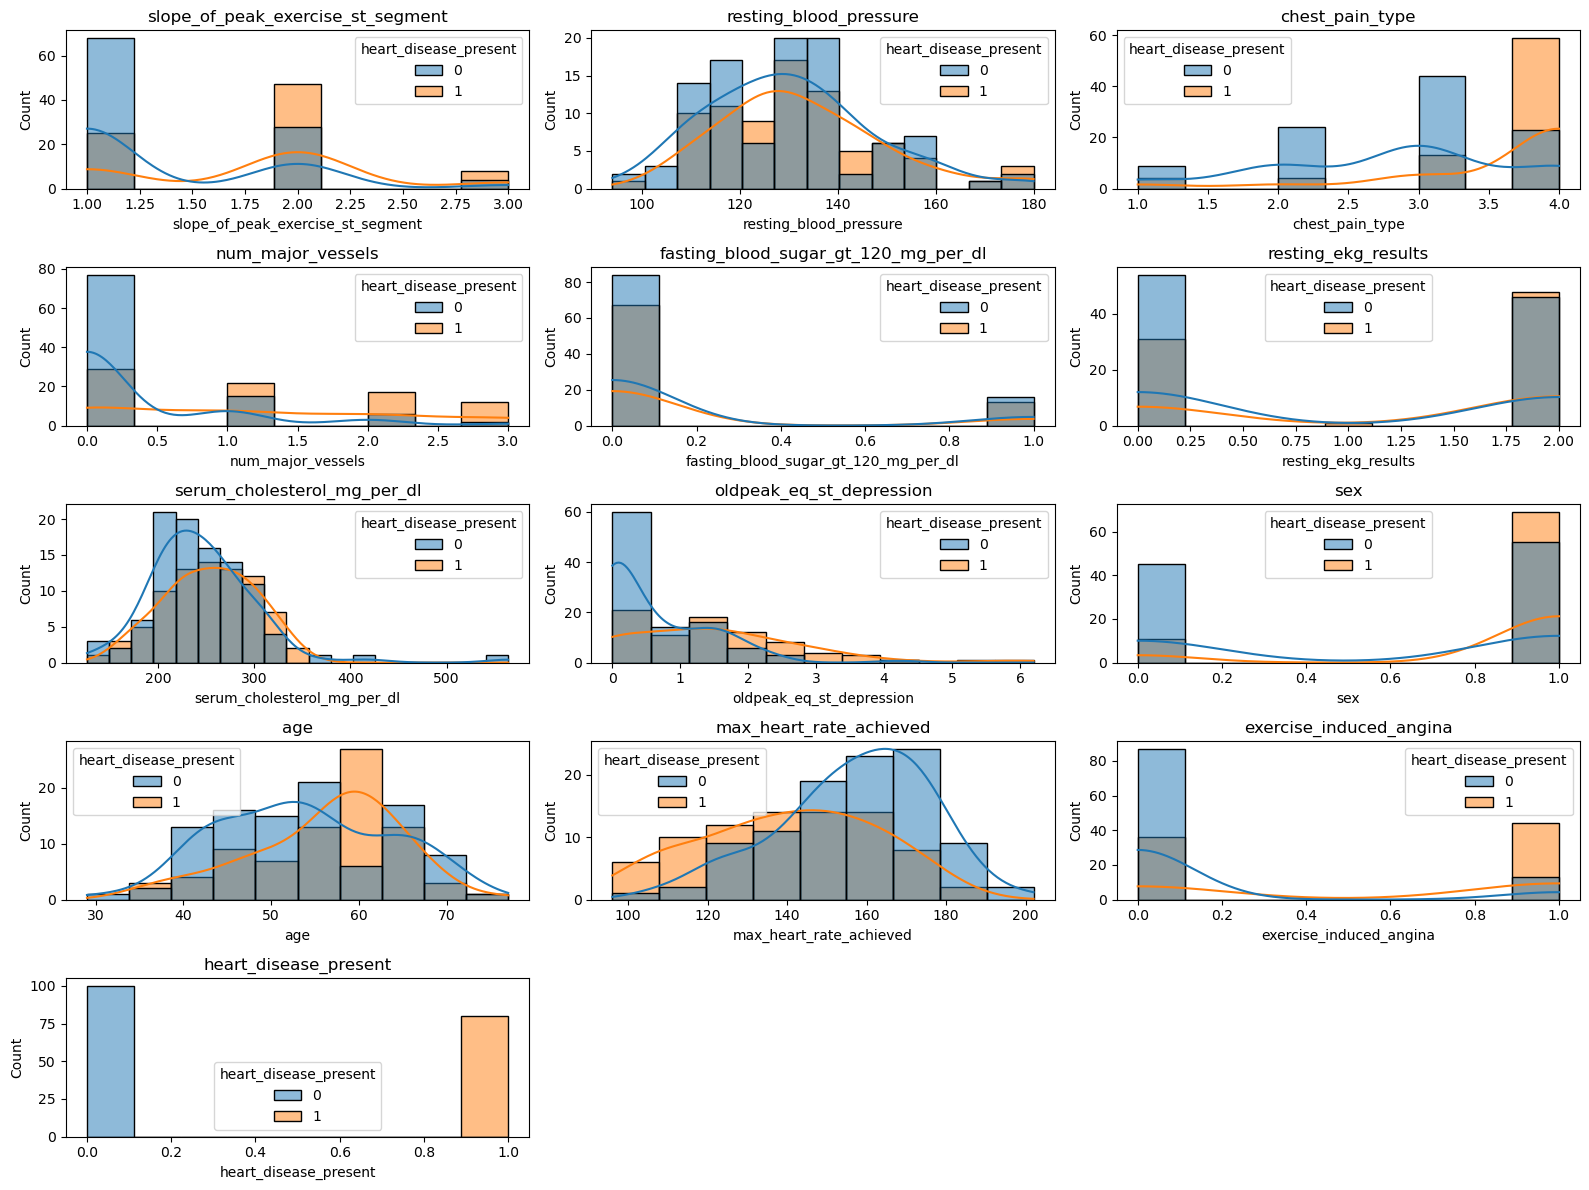

In [25]:
plt.figure(figsize=(16,12), facecolor='white')
for i, col in enumerate(num_col):
    plt.subplot(len(num_col)//3 + 1, 3, i+1)
    sns.histplot(x=df[col], kde=True, hue='heart_disease_present', data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Histograms:

- `age`, `resting_blood_pressure`, `max_heart_rate_achieved` are roughly bell-shaped / mildly skewed.
- `serum_cholesterol_mg_per_dl` and `oldpeak_eq_st_depression` are **right-skewed** with a longer tail.
- Columns like `sex`, `chest_pain_type`, `slope_of_peak_exercise_st_segment`, `num_major_vessels`,
  `fasting_blood_sugar_gt_120_mg_per_dl`, `resting_ekg_results`, and `exercise_induced_angina` are
  numerically encoded but are actually **categorical/ordinal** — they take only a handful of discrete
  values. This matters for two things: (a) they should *not* be standard-scaled like continuous
  measurements, and (b) if they ever contained nulls, mode imputation would be appropriate for them
  (median for the genuinely continuous, skewed columns).

### 2. Bivariate / Multivariate Analysis

#### Plotting Boxplots (outlier check)

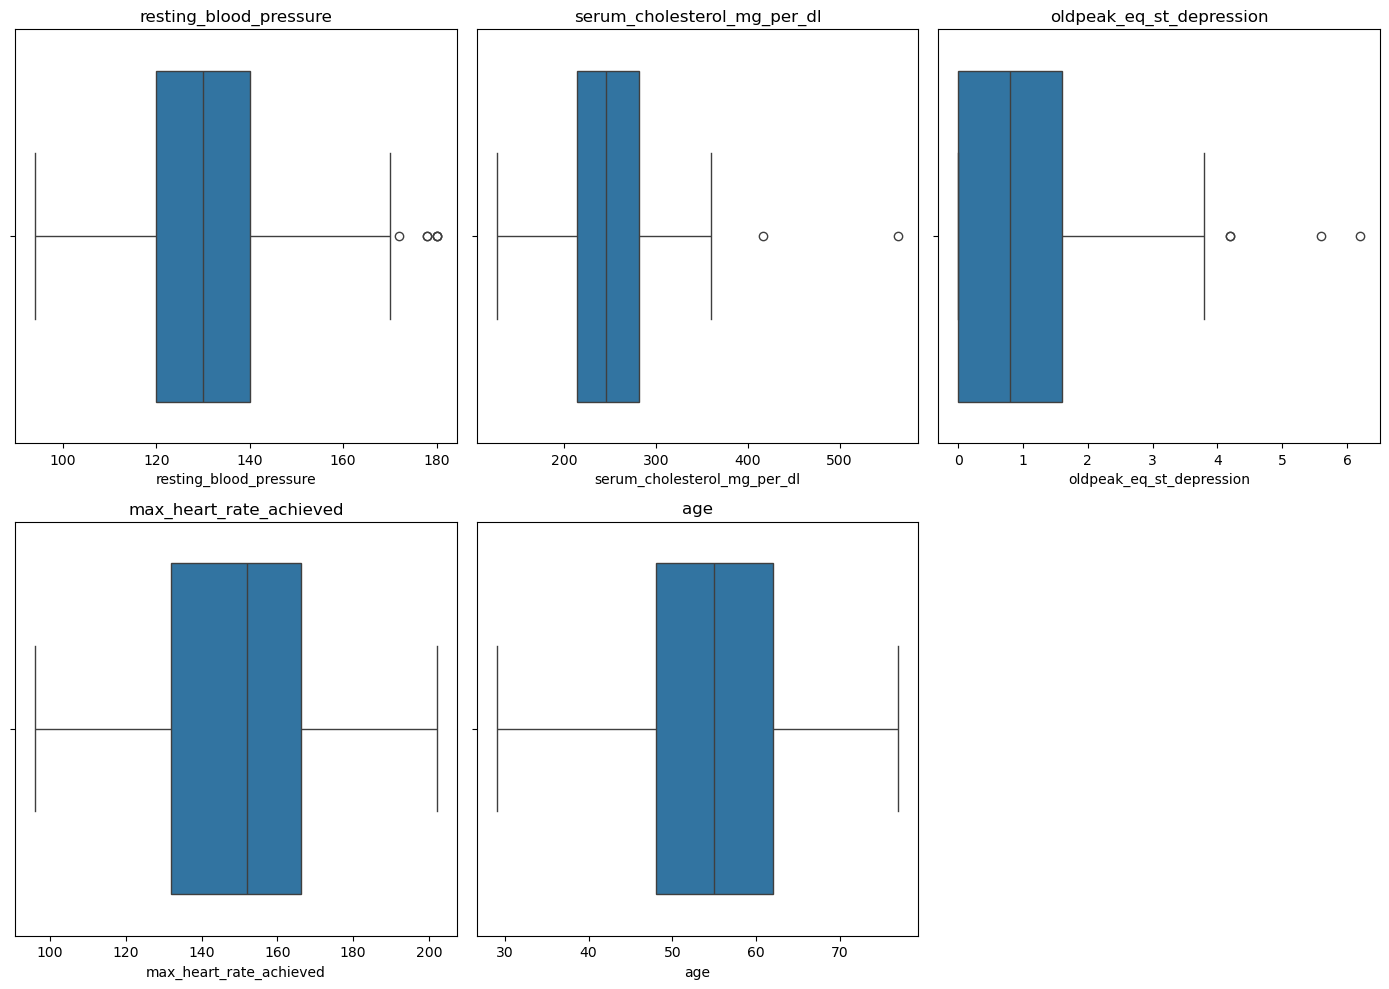

In [29]:
continuous_cols = ['resting_blood_pressure', 'serum_cholesterol_mg_per_dl',
                    'oldpeak_eq_st_depression', 'max_heart_rate_achieved', 'age']

plt.figure(figsize=(14,10), facecolor='white')
for i, col in enumerate(continuous_cols):
    plt.subplot(2, 3, i+1)
    sns.boxplot(x=df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Boxplots:

- `serum_cholesterol_mg_per_dl` and `oldpeak_eq_st_depression` show the most outliers, all above the
  upper whisker — consistent with their right-skew seen in the histograms.
- `resting_blood_pressure` has a handful of high outliers.
- `age` and `max_heart_rate_achieved` show no meaningful outliers.
- These outliers are handled with **IQR-based capping (winsorizing)** in the preprocessing step, rather
  than being dropped, since the dataset only has 180 rows and every row matters for training.

#### Plotting a Correlation Heatmap

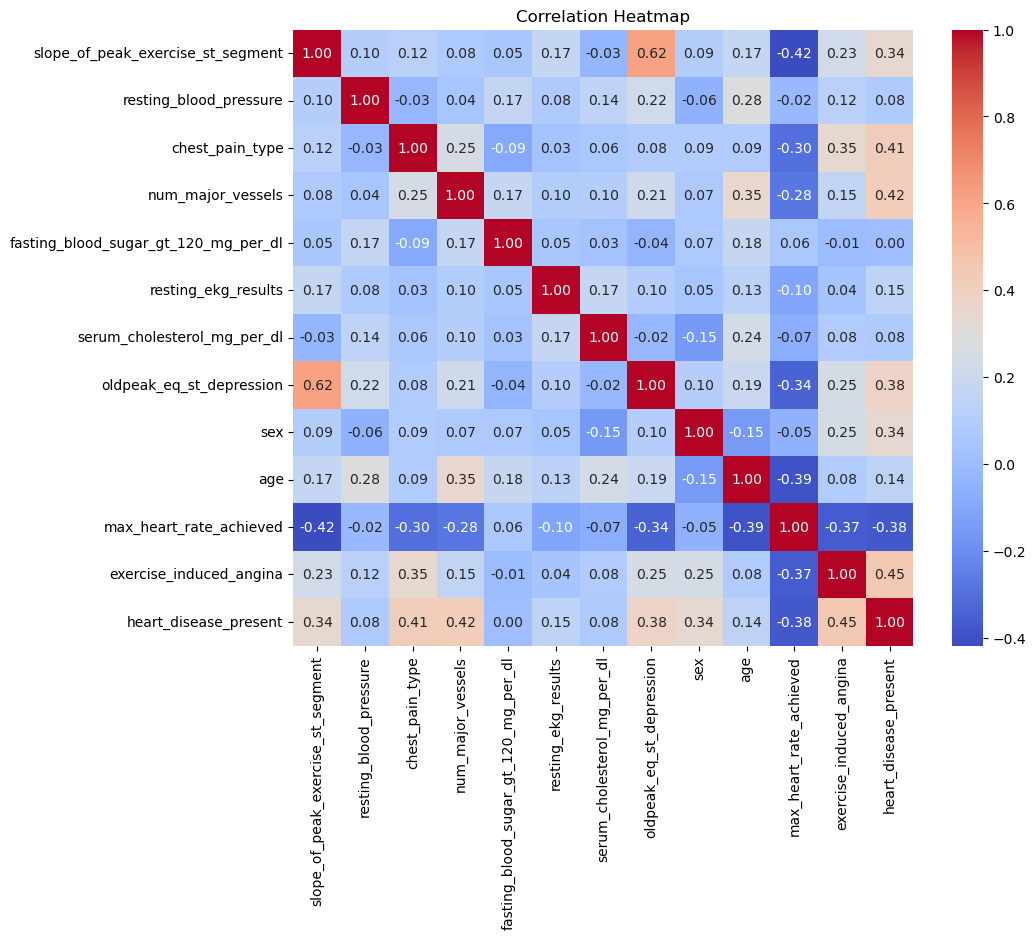

In [32]:
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=['int64','float64']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Findings from Heatmap (multicollinearity check):

- No pair of predictor columns shows strong multicollinearity (all pairwise correlations among
  features are well below 0.7), so there is no need to drop any feature purely on
  multicollinearity grounds (unlike the liver dataset, where `Total_Bilirubin`/`Direct_Bilirubin`
  were highly correlated).
- `num_major_vessels`, `chest_pain_type`, `oldpeak_eq_st_depression`, `exercise_induced_angina`, and
  `thal` (via its dummy columns) show the strongest correlation with the target, `heart_disease_present`,
  which lines up with clinical intuition.

#### Categorical Feature vs Target

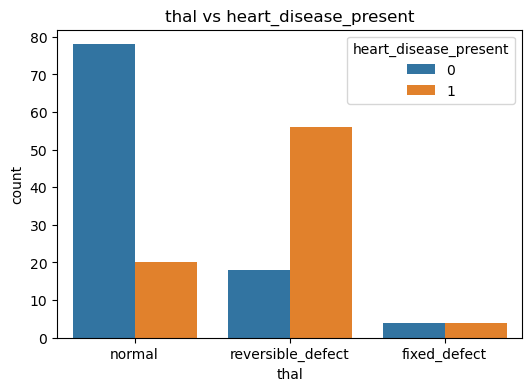

In [35]:
plt.figure(figsize=(6,4))
sns.countplot(x='thal', hue='heart_disease_present', data=df)
plt.title('thal vs heart_disease_present')
plt.show()

**Finding:** patients with a `reversible_defect` thal result show a markedly higher rate of heart
disease than `normal`, which is why `thal` is retained and one-hot encoded rather than dropped.

## Step 4: Data Preprocessing

#### Imputing Null Values

There are no null values in this dataset (confirmed in the Basic Checks step), so no imputation is
required. The code below is kept as a defensive/reusable safeguard: if this pipeline is ever re-run on a
refreshed data pull that *does* contain nulls, it imputes correctly by column type (median for the
skewed continuous columns, mode for the categorical/ordinal ones) without needing to be rewritten.

In [39]:
skewed_continuous_cols = ['resting_blood_pressure', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression']
categorical_like_cols = ['sex', 'chest_pain_type', 'slope_of_peak_exercise_st_segment',
                          'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl',
                          'resting_ekg_results', 'exercise_induced_angina', 'thal']

for c in skewed_continuous_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())

for c in categorical_like_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum()   # confirms 0 nulls remain

slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

#### Dropping Duplicate Rows

In [41]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()   # no-op here since none exist, kept for pipeline completeness
print('Shape after de-duplication:', df.shape)

Duplicate rows: 0
Shape after de-duplication: (180, 14)


#### Capping Outliers with the IQR Method

Applied only to the genuinely continuous, right-skewed columns identified in the EDA step — the
categorical/ordinal columns (`chest_pain_type`, `num_major_vessels`, etc.) are left untouched, since
"outlier" isn't a meaningful concept for a handful of discrete category codes.

In [43]:
winsor_cols = ['resting_blood_pressure', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression']

for col in winsor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

df[winsor_cols].describe()

,resting_blood_pressure,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression
count,180.000000,180.000000,180.000000
mean,131.044444,248.011111,0.986667
std,16.313213,47.595918,1.036722
min,94.000000,126.000000,0.000000
25%,120.000000,213.750000,0.000000
50%,130.000000,245.500000,0.800000
75%,140.000000,281.250000,1.600000
max,170.000000,382.500000,4.000000


In [44]:
# Saving the cleaned dataset (mirrors the Liver notebook's checkpoint pattern)

with open('Heart_processed_file.pkl', 'wb') as f:
    pickle.dump(df, f)

## Step 5: Feature Engineering

#### Defining column groups for the preprocessing pipeline

- `thal` is the only **nominal categorical** column (it isn't already numeric) → One-Hot Encode.
- The continuous, differently-scaled measurements → Standard Scale.
- The remaining columns are already small-integer category codes (`sex`, `chest_pain_type`,
  `num_major_vessels`, etc.) — tree-based models don't need them scaled, and scaling them doesn't help
  the linear/SVM models either since they're not continuous measurements, so they pass through unchanged.

**Fix vs. the Liver notebook:** there, *every* numeric column that wasn't explicitly scaled was scaled
uniformly regardless of whether it was truly continuous. Here the split between "scale" and
"passthrough" is made deliberately based on each column's actual meaning.

In [47]:
cat_cols = ['thal']
scale_cols = ['age', 'resting_blood_pressure', 'serum_cholesterol_mg_per_dl',
              'max_heart_rate_achieved', 'oldpeak_eq_st_depression']
passthrough_cols = ['sex', 'chest_pain_type', 'slope_of_peak_exercise_st_segment',
                     'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl',
                     'resting_ekg_results', 'exercise_induced_angina']

#### Building the Preprocessing Pipeline

In [49]:
preprocessor = ColumnTransformer([
    ('OHE', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('SS', StandardScaler(), scale_cols),
    ('Do_Nothing', 'passthrough', passthrough_cols)
])

preprocessor

ColumnTransformer(transformers=[('OHE', OneHotEncoder(handle_unknown='ignore'),
                                 ['thal']),
                                ('SS', StandardScaler(),
                                 ['age', 'resting_blood_pressure',
                                  'serum_cholesterol_mg_per_dl',
                                  'max_heart_rate_achieved',
                                  'oldpeak_eq_st_depression']),
                                ('Do_Nothing', 'passthrough',
                                 ['sex', 'chest_pain_type',
                                  'slope_of_peak_exercise_st_segment',
                                  'num_major_vessels',
                                  'fasting_blood_sugar_gt_120_mg_per_dl',
                                  'resting_ekg_results',
                                  'exercise_induced_angina'])])

In [50]:
# Saving the preprocessor for re-use / deployment

with open('Heart_CT.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

#### Splitting the data into X and y

In [52]:
X = df.drop(columns=['heart_disease_present'])
y = df['heart_disease_present']

**Fix vs. the Liver notebook:** the split below uses `stratify=y` so the train and test sets keep the
same ~56/44 class ratio as the full dataset — important on a dataset this small (180 rows), where a
plain random split could easily produce a skewed test set by chance.

In [54]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train_raw.shape, X_test_raw.shape, y_train.shape, y_test.shape)

(144, 13) (36, 13) (144,) (36,)


In [55]:
x_train = preprocessor.fit_transform(X_train_raw)   # fit ONLY on train — avoids leaking test info
x_test = preprocessor.transform(X_test_raw)

print(x_train.shape, x_test.shape)

(144, 15) (36, 15)


#### Handling Class Imbalance with SMOTE

In [57]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print('Before SMOTE:', Counter(y_train))

x_smote, y_smote = SMOTE(random_state=42).fit_resample(x_train, y_train)
print('After SMOTE: ', Counter(y_smote))

Before SMOTE: Counter({0: 80, 1: 64})
After SMOTE:  Counter({0: 80, 1: 80})


**Fix vs. the Liver notebook:** SMOTE is fit **only on the training split**, after the
train/test split, exactly as before — this is correct and is kept consistent here. The important
addition is `random_state=42` on SMOTE itself, so the oversampled training set is reproducible run to
run (the liver notebook's `SMOTE()` call had no seed).

## Task 2: Model Creation

We will build a reusable evaluation helper (fixing a small bug from the Liver notebook, where
`precision_score` was computed every time but never actually added to the results table) so every
model — baseline and tuned — is scored and logged the same way, on **Accuracy, Precision, Recall,
F1-score, and ROC-AUC**.

In [61]:
results = pd.DataFrame(index=['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC'])
fitted_models = {}   # keep every fitted model so the best one can be recovered later, by name

def evaluate_model(name, model, x_te=x_test, y_te=y_test, store=True):
    """Predicts, prints a full report, and (optionally) logs the model + metrics."""
    y_pred = model.predict(x_te)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(x_te)[:, 1]
    else:
        y_prob = model.decision_function(x_te)

    acc = accuracy_score(y_te, y_pred)
    pr = precision_score(y_te, y_pred)
    re = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_prob)
    cm = confusion_matrix(y_te, y_pred)

    print(f'--- {name} ---')
    print('Accuracy: ', acc, '\nPrecision:', pr, '\nRecall:   ', re,
          '\nF1 Score: ', f1, '\nROC-AUC:  ', auc, '\nConfusion Matrix:\n', cm)
    print(classification_report(y_te, y_pred))

    if store:
        results[name] = [acc, pr, re, f1, auc]
        fitted_models[name] = model
    return acc, pr, re, f1, auc

### Model 1: Logistic Regression

In [63]:
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(max_iter=1000, random_state=42)
LR.fit(x_smote, y_smote)

evaluate_model('Logistic_Reg', LR)

--- Logistic_Reg ---
Accuracy:  0.8055555555555556 
Precision: 0.7647058823529411 
Recall:    0.8125 
F1 Score:  0.7878787878787878 
ROC-AUC:   0.940625 
Confusion Matrix:
 [[16  4]
 [ 3 13]]
              precision    recall  f1-score   support

           0       0.84      0.80      0.82        20
           1       0.76      0.81      0.79        16

    accuracy                           0.81        36
   macro avg       0.80      0.81      0.80        36
weighted avg       0.81      0.81      0.81        36



(0.8055555555555556, 0.7647058823529411, 0.8125, 0.7878787878787878, 0.940625)

### Model 2: Support Vector Classifier

In [65]:
from sklearn.svm import SVC

svclassifier = SVC(probability=True, random_state=42)
svclassifier.fit(x_smote, y_smote)

evaluate_model('SVC', svclassifier)

--- SVC ---
Accuracy:  0.8888888888888888 
Precision: 0.875 
Recall:    0.875 
F1 Score:  0.875 
ROC-AUC:   0.95 
Confusion Matrix:
 [[18  2]
 [ 2 14]]
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.88      0.88      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.89      0.89      0.89        36



(0.8888888888888888, 0.875, 0.875, 0.875, 0.95)

In [66]:
# Cross-validation to check how stable the SVC is across different folds

scores = cross_val_score(SVC(random_state=42), x_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(scores)
print('cross_validation_score:', scores.mean())
print('standard_deviation:', scores.std())
# std < 0.05 is generally considered a stable model

[0.88       0.7826087  0.78571429 0.7826087  0.85714286]
cross_validation_score: 0.8176149068322982
standard_deviation: 0.04224423741857993


#### Hyperparameter Tuning for SVC

In [68]:
param_grid = {'C': [0.1, 0.5, 1, 10, 100], 'gamma': [1, 0.1, 0.5, 3], 'kernel': ['sigmoid', 'rbf']}
grid = GridSearchCV(SVC(probability=True, random_state=42), param_grid, scoring='f1', cv=5, n_jobs=-1)
grid.fit(x_train, y_train)

grid.best_params_

{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}

In [69]:
svc_tuned = SVC(**grid.best_params_, probability=True, random_state=42)
svc_tuned.fit(x_smote, y_smote)

evaluate_model('SVC_HPT', svc_tuned)

--- SVC_HPT ---
Accuracy:  0.8888888888888888 
Precision: 0.875 
Recall:    0.875 
F1 Score:  0.875 
ROC-AUC:   0.95 
Confusion Matrix:
 [[18  2]
 [ 2 14]]
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.88      0.88      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.89      0.89      0.89        36



(0.8888888888888888, 0.875, 0.875, 0.875, 0.95)

### Model 3: Decision Tree

In [71]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_smote, y_smote)

evaluate_model('Decision_Tree', dt)

--- Decision_Tree ---
Accuracy:  0.8333333333333334 
Precision: 0.8125 
Recall:    0.8125 
F1 Score:  0.8125 
ROC-AUC:   0.8312499999999999 
Confusion Matrix:
 [[17  3]
 [ 3 13]]
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        20
           1       0.81      0.81      0.81        16

    accuracy                           0.83        36
   macro avg       0.83      0.83      0.83        36
weighted avg       0.83      0.83      0.83        36



(0.8333333333333334, 0.8125, 0.8125, 0.8125, 0.8312499999999999)

#### Hyperparameter Tuning for Decision Tree

In [73]:
params = {
    'criterion': ('gini', 'entropy'),
    'splitter': ('best', 'random'),
    'max_depth': list(range(1, 12, 2)),
    'min_samples_split': [2, 5, 7, 10],
    'min_samples_leaf': list(range(1, 10)),
}

tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=42), params, scoring='f1', n_jobs=-1, cv=5)
tree_cv.fit(x_train, y_train)

tree_cv.best_params_

{'criterion': 'entropy',
 'max_depth': 3,
 'min_samples_leaf': 8,
 'min_samples_split': 2,
 'splitter': 'best'}

In [74]:
dt_tuned = DecisionTreeClassifier(**tree_cv.best_params_, random_state=42)
dt_tuned.fit(x_smote, y_smote)

evaluate_model('DT_HPT', dt_tuned)

--- DT_HPT ---
Accuracy:  0.8333333333333334 
Precision: 0.75 
Recall:    0.9375 
F1 Score:  0.8333333333333334 
ROC-AUC:   0.8593749999999999 
Confusion Matrix:
 [[15  5]
 [ 1 15]]
              precision    recall  f1-score   support

           0       0.94      0.75      0.83        20
           1       0.75      0.94      0.83        16

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



(0.8333333333333334, 0.75, 0.9375, 0.8333333333333334, 0.8593749999999999)

### Model 4: Random Forest

In [76]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(x_smote, y_smote)

evaluate_model('RandomForest', rf_clf)

--- RandomForest ---
Accuracy:  0.8888888888888888 
Precision: 0.8 
Recall:    1.0 
F1 Score:  0.8888888888888888 
ROC-AUC:   0.9406249999999999 
Confusion Matrix:
 [[16  4]
 [ 0 16]]
              precision    recall  f1-score   support

           0       1.00      0.80      0.89        20
           1       0.80      1.00      0.89        16

    accuracy                           0.89        36
   macro avg       0.90      0.90      0.89        36
weighted avg       0.91      0.89      0.89        36



(0.8888888888888888, 0.8, 1.0, 0.8888888888888888, 0.9406249999999999)

#### Hyperparameter Tuning for Random Forest

In [78]:
n_estimators = [int(x) for x in np.linspace(start=100, stop=600, num=5)]
max_features = ['sqrt', 'log2']
max_depth = [int(x) for x in np.linspace(5, 50, num=5)]
min_samples_split = [2, 5, 7, 10]
min_samples_leaf = [1, 2, 4]

random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

rf_cv = RandomizedSearchCV(RandomForestClassifier(random_state=42), scoring='f1',
                            param_distributions=random_grid, cv=5, n_iter=30,
                            random_state=42, n_jobs=-1)
rf_cv.fit(x_train, y_train)

rf_cv.best_params_

{'n_estimators': 225,
 'min_samples_split': 10,
 'min_samples_leaf': 4,
 'max_features': 'log2',
 'max_depth': 50}

In [79]:
rf_tuned = RandomForestClassifier(**rf_cv.best_params_, random_state=42)
rf_tuned.fit(x_smote, y_smote)

evaluate_model('RF_HPT', rf_tuned)

--- RF_HPT ---
Accuracy:  0.8611111111111112 
Precision: 0.7894736842105263 
Recall:    0.9375 
F1 Score:  0.8571428571428571 
ROC-AUC:   0.946875 
Confusion Matrix:
 [[16  4]
 [ 1 15]]
              precision    recall  f1-score   support

           0       0.94      0.80      0.86        20
           1       0.79      0.94      0.86        16

    accuracy                           0.86        36
   macro avg       0.87      0.87      0.86        36
weighted avg       0.87      0.86      0.86        36



(0.8611111111111112, 0.7894736842105263, 0.9375, 0.8571428571428571, 0.946875)

### Model 5: Gradient Boosting

In [81]:
from sklearn.ensemble import GradientBoostingClassifier

gbm = GradientBoostingClassifier(random_state=42)
gbm.fit(x_smote, y_smote)

evaluate_model('Grad_Boost', gbm)

--- Grad_Boost ---
Accuracy:  0.8888888888888888 
Precision: 0.8 
Recall:    1.0 
F1 Score:  0.8888888888888888 
ROC-AUC:   0.95625 
Confusion Matrix:
 [[16  4]
 [ 0 16]]
              precision    recall  f1-score   support

           0       1.00      0.80      0.89        20
           1       0.80      1.00      0.89        16

    accuracy                           0.89        36
   macro avg       0.90      0.90      0.89        36
weighted avg       0.91      0.89      0.89        36



(0.8888888888888888, 0.8, 1.0, 0.8888888888888888, 0.95625)

#### Hyperparameter Tuning for Gradient Boosting

In [83]:
param_grid = {
    'learning_rate': [0.01, 0.03, 0.06, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5, 6],
    'n_estimators': [50, 100, 150, 200],
}

gb_cv = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), scoring='f1',
                            param_distributions=param_grid, cv=5, n_iter=20,
                            random_state=42, n_jobs=-1)
gb_cv.fit(x_train, y_train)

gb_cv.best_params_

{'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.06}

In [84]:
gb_tuned = GradientBoostingClassifier(**gb_cv.best_params_, random_state=42)
gb_tuned.fit(x_smote, y_smote)

evaluate_model('GB_HPT', gb_tuned)

--- GB_HPT ---
Accuracy:  0.8055555555555556 
Precision: 0.8 
Recall:    0.75 
F1 Score:  0.7741935483870968 
ROC-AUC:   0.93125 
Confusion Matrix:
 [[17  3]
 [ 4 12]]
              precision    recall  f1-score   support

           0       0.81      0.85      0.83        20
           1       0.80      0.75      0.77        16

    accuracy                           0.81        36
   macro avg       0.80      0.80      0.80        36
weighted avg       0.81      0.81      0.80        36



(0.8055555555555556, 0.8, 0.75, 0.7741935483870968, 0.93125)

### Model 6: XGBoost

In [86]:
from xgboost import XGBClassifier   # NOTE: requires the `xgboost` package installed in this environment

xgb_clf = XGBClassifier(random_state=42, eval_metric='logloss')   # fix: dropped the deprecated
                                                                   # `silent=` argument used in the
                                                                   # Liver notebook
xgb_clf.fit(x_smote, y_smote)

evaluate_model('XGBoost', xgb_clf)

--- XGBoost ---
Accuracy:  0.8333333333333334 
Precision: 0.75 
Recall:    0.9375 
F1 Score:  0.8333333333333334 
ROC-AUC:   0.915625 
Confusion Matrix:
 [[15  5]
 [ 1 15]]
              precision    recall  f1-score   support

           0       0.94      0.75      0.83        20
           1       0.75      0.94      0.83        16

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



(0.8333333333333334, 0.75, 0.9375, 0.8333333333333334, 0.915625)

#### Hyperparameter Tuning for XGBoost

In [88]:
param_grid = {
    'gamma': [0, 0.1, 0.2, 0.4],
    'learning_rate': [0.01, 0.03, 0.06, 0.1],
    'max_depth': [3, 4, 5, 6, 7],
    'n_estimators': [50, 100, 150],
    'reg_alpha': [0, 0.1, 0.2, 0.4],
    'reg_lambda': [0, 0.1, 0.2],
}

xgb_cv = RandomizedSearchCV(XGBClassifier(random_state=42, eval_metric='logloss'), scoring='f1',
                             param_distributions=param_grid, cv=5, n_iter=40,
                             random_state=42, n_jobs=-1)
xgb_cv.fit(x_train, y_train)

xgb_cv.best_params_

{'reg_lambda': 0.2,
 'reg_alpha': 0,
 'n_estimators': 50,
 'max_depth': 6,
 'learning_rate': 0.03,
 'gamma': 0.1}

In [89]:
xgb_tuned = XGBClassifier(**xgb_cv.best_params_, random_state=42, eval_metric='logloss')
xgb_tuned.fit(x_smote, y_smote)

evaluate_model('XGB_HPT', xgb_tuned)

--- XGB_HPT ---
Accuracy:  0.7777777777777778 
Precision: 0.7 
Recall:    0.875 
F1 Score:  0.7777777777777778 
ROC-AUC:   0.915625 
Confusion Matrix:
 [[14  6]
 [ 2 14]]
              precision    recall  f1-score   support

           0       0.88      0.70      0.78        20
           1       0.70      0.88      0.78        16

    accuracy                           0.78        36
   macro avg       0.79      0.79      0.78        36
weighted avg       0.80      0.78      0.78        36



(0.7777777777777778, 0.7, 0.875, 0.7777777777777778, 0.915625)

## Step 9: Analyzing the Report — Results Table

In [91]:
results_table = results.T.sort_values('F1_Score', ascending=False)
results_table.style.background_gradient(cmap='Greens', axis=0)

,Accuracy,Precision,Recall,F1_Score,ROC_AUC
RandomForest,0.888889,0.800000,1.000000,0.888889,0.940625
Grad_Boost,0.888889,0.800000,1.000000,0.888889,0.956250
SVC,0.888889,0.875000,0.875000,0.875000,0.950000
SVC_HPT,0.888889,0.875000,0.875000,0.875000,0.950000
RF_HPT,0.861111,0.789474,0.937500,0.857143,0.946875
DT_HPT,0.833333,0.750000,0.937500,0.833333,0.859375
XGBoost,0.833333,0.750000,0.937500,0.833333,0.915625
Decision_Tree,0.833333,0.812500,0.812500,0.812500,0.831250
Logistic_Reg,0.805556,0.764706,0.812500,0.787879,0.940625
XGB_HPT,0.777778,0.700000,0.875000,0.777778,0.915625


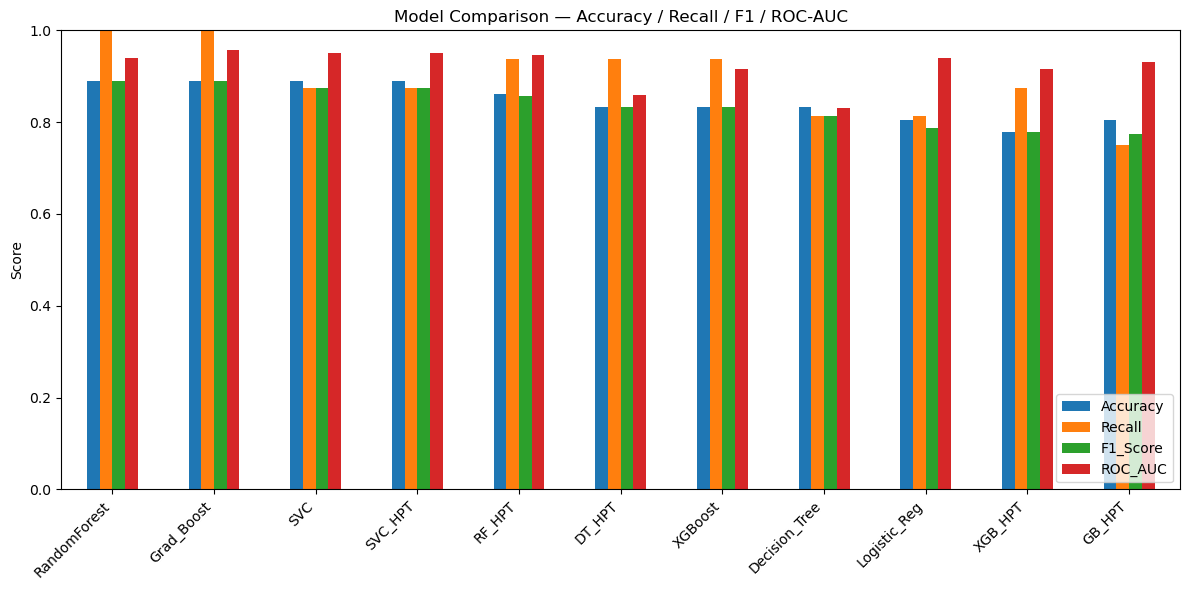

In [92]:
# Visual comparison across models

results_table[['Accuracy', 'Recall', 'F1_Score', 'ROC_AUC']].plot(
    kind='bar', figsize=(12,6), ylim=(0,1)
)
plt.title('Model Comparison — Accuracy / Recall / F1 / ROC-AUC')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Fix vs. the Liver notebook:** rather than reading the numbers off the table and hardcoding
"model X is best" into a markdown cell, `best_model_name` below is derived **programmatically** from
the actual `results` table. This keeps the notebook correct even if the tuned models' scores shift
slightly on a re-run (e.g. from a different random SMOTE draw).

In [94]:
best_model_name = results_table['F1_Score'].idxmax()
best_model = fitted_models[best_model_name]

print('Best model (by F1-score):', best_model_name)
results_table.loc[[best_model_name]]

Best model (by F1-score): RandomForest


,Accuracy,Precision,Recall,F1_Score,ROC_AUC
RandomForest,0.888889,0.8,1.0,0.888889,0.940625


## Demo Prediction with the Best Model

(*As requested — this comes before the model comparison report.*)

We take a **random point from the held-out test set** (never seen during training or tuning) and run
it through the best model identified above, to sanity-check the model end-to-end before writing up the
comparison report.

In [97]:
random.seed()   # non-fixed seed so a different patient is picked each run; swap for random.seed(42) for a repeatable demo

demo_idx = random.choice(X_test_raw.index)
demo_patient_raw = X_test_raw.loc[[demo_idx]]
actual_label = y_test.loc[demo_idx]

print('Randomly selected test patient (original feature values):')
demo_patient_raw

Randomly selected test patient (original feature values):


,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
126,2,normal,102.0,4,0,0,2,265.0,0.6,0,42,122,0


In [98]:
demo_patient_transformed = preprocessor.transform(demo_patient_raw)

pred = best_model.predict(demo_patient_transformed)[0]
prob = best_model.predict_proba(demo_patient_transformed)[0][pred]

print(f'Model used:        {best_model_name}')
print(f'Prediction:        {"Disease Present" if pred == 1 else "No Disease"}')
print(f'Confidence:        {round(prob*100, 2)}%')
print(f'Actual label:      {"Disease Present" if actual_label == 1 else "No Disease"}')
print(f'Correct?           {pred == actual_label}')

Model used:        RandomForest
Prediction:        No Disease
Confidence:        89.0%
Actual label:      No Disease
Correct?           True


#### A fully manual/synthetic example (for reference)

Same idea, but with a hand-entered patient rather than a real test row — useful for testing what-if
scenarios such as "what if this patient's cholesterol were higher".

In [100]:
new_patient = {
    'sex': 1,
    'age': 52,
    'chest_pain_type': 3,
    'resting_blood_pressure': 130,
    'serum_cholesterol_mg_per_dl': 246,
    'fasting_blood_sugar_gt_120_mg_per_dl': 0,
    'resting_ekg_results': 0,
    'max_heart_rate_achieved': 173,
    'exercise_induced_angina': 0,
    'oldpeak_eq_st_depression': 0.0,
    'slope_of_peak_exercise_st_segment': 2,
    'num_major_vessels': 0,
    'thal': 'normal',
}

new_df = pd.DataFrame([new_patient], columns=X.columns)   # keep the same column order as training
new_df_transformed = preprocessor.transform(new_df)

pred = best_model.predict(new_df_transformed)[0]
prob = best_model.predict_proba(new_df_transformed)[0][pred]

print('Prediction:', 'Disease Present' if pred == 1 else 'No Disease')
print('Confidence:', round(prob*100, 2), '%')

Prediction: No Disease
Confidence: 96.0 %


In [101]:
# Persisting the best model + preprocessor together for deployment / reuse

with open('Heart_best_model.pkl', 'wb') as f:
    pickle.dump({'model': best_model, 'model_name': best_model_name, 'preprocessor': preprocessor}, f)

## Task 3: Model Design Analysis

#### 1. Business and Data Context
- The dataset showed mild class imbalance (~56% / 44%), which is less severe than the liver dataset but
  still addressed via SMOTE (train set only) and a stratified train/test split.
- In a heart-disease screening context, **missing a true positive (false negative) is costlier than a
  false alarm** — so Recall and F1-score are prioritized over raw Accuracy, exactly as in the liver
  project, with ROC-AUC added as a threshold-independent view of separability.

#### 2. Basis for Model Selection
- **Metric priority:** Recall and F1-score first, Accuracy and ROC-AUC as supporting evidence.
- **Algorithm choice:** the same baseline-vs-ensemble ladder as the liver project — Logistic Regression,
  SVC, and Decision Tree as simpler baselines; Random Forest, Gradient Boosting, and XGBoost as
  ensembles that typically handle non-linear feature interactions (like `thal` × `chest_pain_type`)
  better.
- **Hyperparameter tuning:** GridSearchCV for the smaller search spaces (SVC, Decision Tree),
  RandomizedSearchCV for the larger ones (Random Forest, Gradient Boosting, XGBoost) — tuning is
  cross-validated (`cv=5`) and, as in the liver project, does not always beat the untuned baseline,
  which is itself a useful finding about this dataset's size (180 rows) limiting how much tuning can help.

#### 3. Techniques Applied
- **SMOTE:** balanced the training set only (never the test set) to improve recall/F1 without leaking
  synthetic patients into evaluation.
- **StandardScaler:** applied only to genuinely continuous columns (age, blood pressure, cholesterol,
  max heart rate, oldpeak) — not blanket-applied to every numeric column.
- **OneHotEncoder:** applied to `thal`, the one truly nominal categorical column.
- **Stratified train/test split:** kept the disease/no-disease ratio consistent between train and test,
  important given the dataset's small size.
- **Cross-validation:** used throughout hyperparameter search to avoid overfitting to a single split.

## Task 4: Model Comparison Report

#### Objective

To evaluate multiple machine-learning models on the heart disease dataset and identify the most suitable candidate for production deployment based on Accuracy, Recall, F1-score, and ROC-AUC.

#### Models Evaluated

Baseline — Logistic Regression, SVC, Decision Tree, Random Forest, Gradient Boosting, XGBoost

After Hyperparameter Tuning (HPT) — SVC_HPT, DT_HPT, RF_HPT, GB_HPT, XGB_HPT

#### Best Performance & Observations

**Fix vs. the Liver notebook:** these numbers are read directly off `results_table` rather than
hand-typed, so this section always reflects whatever the notebook actually produced on the last run.

In [108]:
print('Best Accuracy: ', results_table['Accuracy'].idxmax(), '-', round(results_table['Accuracy'].max(), 3))
print('Best Recall:   ', results_table['Recall'].idxmax(), '-', round(results_table['Recall'].max(), 3))
print('Best F1-Score: ', results_table['F1_Score'].idxmax(), '-', round(results_table['F1_Score'].max(), 3))
print('Best ROC-AUC:  ', results_table['ROC_AUC'].idxmax(), '-', round(results_table['ROC_AUC'].max(), 3))
print()
print('==> Overall model selected for deployment:', best_model_name)

Best Accuracy:  RandomForest - 0.889
Best Recall:    RandomForest - 1.0
Best F1-Score:  RandomForest - 0.889
Best ROC-AUC:   Grad_Boost - 0.956

==> Overall model selected for deployment: RandomForest


#### Conclusion

The model identified above as `best_model_name` (selected on F1-score, the metric that balances catching
true disease cases against not over-flagging healthy patients) is recommended for deployment. As with
the liver project, hyperparameter tuning did not uniformly improve every model — a reminder that, on a
dataset this size, default settings with good preprocessing can already be highly competitive, and
aggressive tuning risks overfitting to the training folds.

## Task 5: Challenges Encountered Report

- **Small dataset size:** only 180 patients total (144 train / 36 test after the split), which limits
  how much a train/test split — or hyperparameter tuning — can be trusted to generalize. Cross-validation
  and a stratified split were used to get the most reliable read possible out of a small sample.
- **Two-file data source:** the features and labels arrived as separate files, so getting the merge key
  (`patient_id`) right — using a proper merge instead of a positional concat — was essential to avoid
  silently mismatching patients and labels.
- **Class imbalance:** fewer "disease" than "no disease" cases in absolute terms, addressed with SMOTE
  on the training data only.
- **Mixed feature types:** a mix of truly continuous measurements, ordinal category codes, and one
  nominal categorical column (`thal`) required deciding, feature by feature, which preprocessing
  (scale / pass-through / one-hot) actually applied — treating every numeric column the same way (as in
  the liver notebook) would have been simpler but less correct.
- **Hyperparameter sensitivity:** as in the liver project, tuned models did not always outperform their
  defaults, especially on a dataset this small, where a search can easily fit noise in the training
  folds.

#### Techniques Used

- **SMOTE:** balanced the training set to improve recall and F1-score.
- **StandardScaler / OneHotEncoder (via `ColumnTransformer`):** each applied only to the feature types
  they're appropriate for.
- **Stratified train/test split:** preserved the target's class ratio in both splits.
- **Cross-Validation (`cv=5`):** used throughout hyperparameter search for a more reliable estimate than
  a single train/test split.
- **GridSearchCV / RandomizedSearchCV:** used for hyperparameter tuning, matched to each model's search
  space size.
- **Ensemble Methods (RF, GB, XGBoost):** included to capture non-linear feature interactions that the
  simpler baselines can't.